# O que o líder do mercado mantém no ar, e o que isso diz (e não diz) sobre o que funciona?

Todo gestor de tráfego abre a biblioteca de anúncios do concorrente, ordena por "dias no ar" e conclui: *este está
há 70 dias rodando, então funciona*.

Este caderno testa o quanto essa leitura se sustenta, com a coleta de 10/11/2026 dos anúncios **ativos** do
concorrente líder do segmento de música personalizada como presente: 1.342 anúncios (93 no Brasil, 1.249 nos
Estados Unidos).

O extrato em `data/` é anonimizado: não tem nome, página, domínio, link, id original, texto nem mídia. Cada anúncio
traz país, data de início, dias no ar, formato, o grupo de criativo (o mesmo vídeo reaproveitado), a classificação do
vídeo e atributos derivados do texto por regras fixas (`src/anuncios_concorrente/texto.py`).

In [1]:
%matplotlib inline
import warnings

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from anuncios_concorrente import analise, dados, graficos

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.2f}".replace(",", "§").replace(".", ",").replace("§", "."))
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)


def mostrar(figura):
    display(figura)
    plt.close(figura)


anuncios, coleta = dados.carregar_anuncios(), dados.carregar_coleta()
eua = dados.do_pais(anuncios, "US")
analise.resumo_da_coleta(anuncios).T

,BR,US
anúncios,"93,00","1.249,00"
grupos de criativo,"89,00","485,00"
textos distintos,"2,00","58,00"
datas de lançamento,"4,00","48,00"
páginas,"1,00","2,00"
idade média (dias),"9,92","27,60"
idade mediana (dias),"9,00","22,00"
idade máxima (dias),"20,00","76,00"
com vídeo,"1,00","0,94"
com classificação do vídeo,"1,00","0,44"


## 1. O dado é uma foto, não um histórico

Três coisas que a foto esconde:

1. **"Dias no ar" é a idade do anúncio, não a duração.** Todo anúncio da foto ainda está vivo; ninguém sabe quanto
   mais ele vai durar.
2. **Anúncio longo aparece mais.** Um anúncio que fica 60 dias no ar tem 60 chances de estar numa foto tirada num dia
   qualquer; um que fica 3 dias tem 3. É o paradoxo da inspeção: a foto sobre-representa os longevos.
3. **Quem já saiu não aparece.** Os anúncios desligados na primeira semana são invisíveis.

Para ver o tamanho do erro, simulo anúncios cuja duração eu conheço (média de 20 dias em todos os cenários), tiro uma
"foto" e comparo duas leituras com a verdade: a **ingênua** (média de dias no ar) e a **corrigida** (seção 2).

In [2]:
simulacao = analise.simulacao()
colunas = ["duração", "ritmo", "duração média real", "leitura ingênua", "erro da ingênua", "corrigida", "erro da corrigida", "duração real dos fotografados"]
simulacao[colunas]

,duração,ritmo,duração média real,leitura ingênua,erro da ingênua,corrigida,erro da corrigida,duração real dos fotografados
0,Todo anúncio dura 20 dias,Ritmo constante,"20,00","10,54","-0,47","18,12","-0,09","20,00"
1,Todo anúncio dura 20 dias,Ritmo dobra a cada 30 dias,"20,00","9,71","-0,51","14,96","-0,25","20,00"
2,Todo anúncio dura 20 dias,Lançamentos em lotes irregulares,"20,00","10,44","-0,48","11,35","-0,43","20,00"
3,Todo anúncio dura 20 dias,Conta começou há 30 dias,"20,00","10,49","-0,48","17,89","-0,11","20,00"
4,Risco constante de sair do ar,Ritmo constante,"20,00","19,96","-0,00","19,01","-0,05","38,99"
5,Risco constante de sair do ar,Ritmo dobra a cada 30 dias,"20,00","13,97","-0,30","13,62","-0,32","33,07"
6,Risco constante de sair do ar,Lançamentos em lotes irregulares,"20,00","21,99","0,10","18,48","-0,08","41,02"
7,Risco constante de sair do ar,Conta começou há 30 dias,"20,00","11,83","-0,41","15,34","-0,23","30,86"
8,"Muitos testes curtos, poucos anúncios longos",Ritmo constante,"20,00","64,80","2,24","19,96","-0,00","129,15"
9,"Muitos testes curtos, poucos anúncios longos",Ritmo dobra a cada 30 dias,"20,00","19,16","-0,04","9,36","-0,53","68,65"


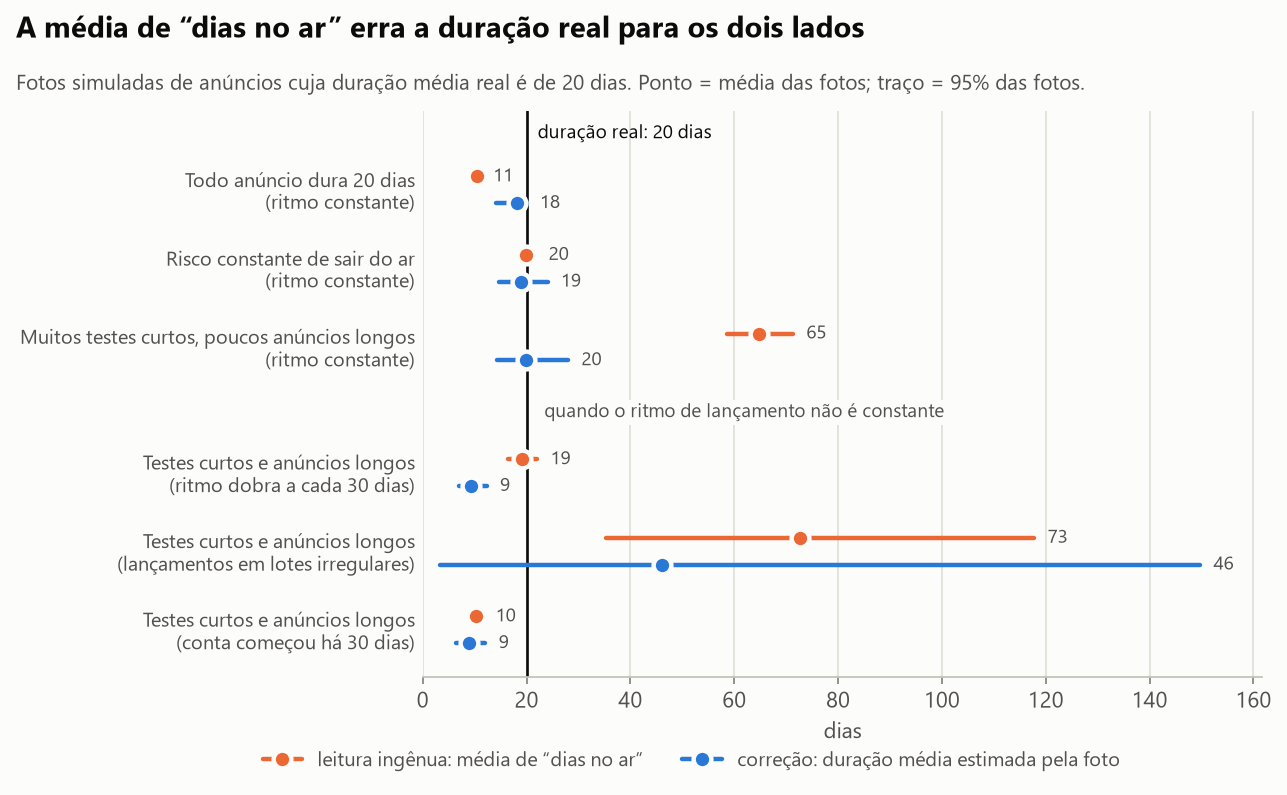

In [3]:
mostrar(graficos.simulacao(simulacao))

Com ritmo de lançamento constante, a teoria diz quanto a foto mostra: a idade média é `E[D(D+1)] / (2·E[D])`.
Se todo anúncio dura 20 dias, a foto mostra 10,5 (metade). Se o risco de sair do ar é constante, mostra 20 (acerta
por coincidência matemática). Se há muitos testes curtos e poucos anúncios longos, mostra 65: mais que o triplo.
**A leitura ingênua erra para os dois lados, e o lado depende de uma coisa que a foto não revela.**

A última coluna é o viés pelo comprimento: os anúncios que aparecem na foto duram, em média, muito mais que o
anúncio típico (129 dias contra 20 no cenário de cauda longa).

A correção acerta quando o ritmo é constante e erra quando não é: se o anunciante vem acelerando, ela subestima; se
lança em lotes, uma foto sozinha pode dar quase qualquer número.

## 2. O estimador: da distribuição das idades para a curva de sobrevivência

Em dias inteiros: idade `a = 1` para quem foi lançado no dia da foto; `S(a)` é a fração dos anúncios que chega ao
dia `a`. Um anúncio lançado há `a − 1` dias aparece na foto se durou pelo menos `a` dias. Então o número esperado de
anúncios com idade `a` é

`n(a) = taxa × w(a) × S(a)`, com `w(a)` = ritmo relativo de lançamento naquele dia.

Com ritmo constante (`w = 1`), as idades têm distribuição proporcional a `S`. Daí: duração média = `1 / p(1)` e
`S(a) = p(a) / p(1)`. Como `S` não pode subir, `p` é estimada como a melhor sequência não crescente (estimador de
Grenander, por regressão isotônica, implementada em `sobrevivencia.py` e conferida contra o scikit-learn nos testes).

Na foto real dos EUA:

In [4]:
duracao = analise.duracao_estimada(eua)
pd.Series({k: v for k, v in duracao.items() if k not in ("tabela", "so_com_registro_no_dia_da_coleta")})

anuncios             1.249,00
janela_em_dias          76,00
media_ingenua           27,60
mediana_ingenua         22,00
duracao_corrigida       17,97
lancados_por_dia        69,50
lancados_na_janela   5.282,00
ja_sairam_do_ar      4.033,00
fracao_que_ja_saiu       0,76
chegam_ao_dia_8          0,42
chegam_ao_dia_15         0,42
chegam_ao_dia_31         0,16
chegam_ao_dia_61         0,16
dtype: float64

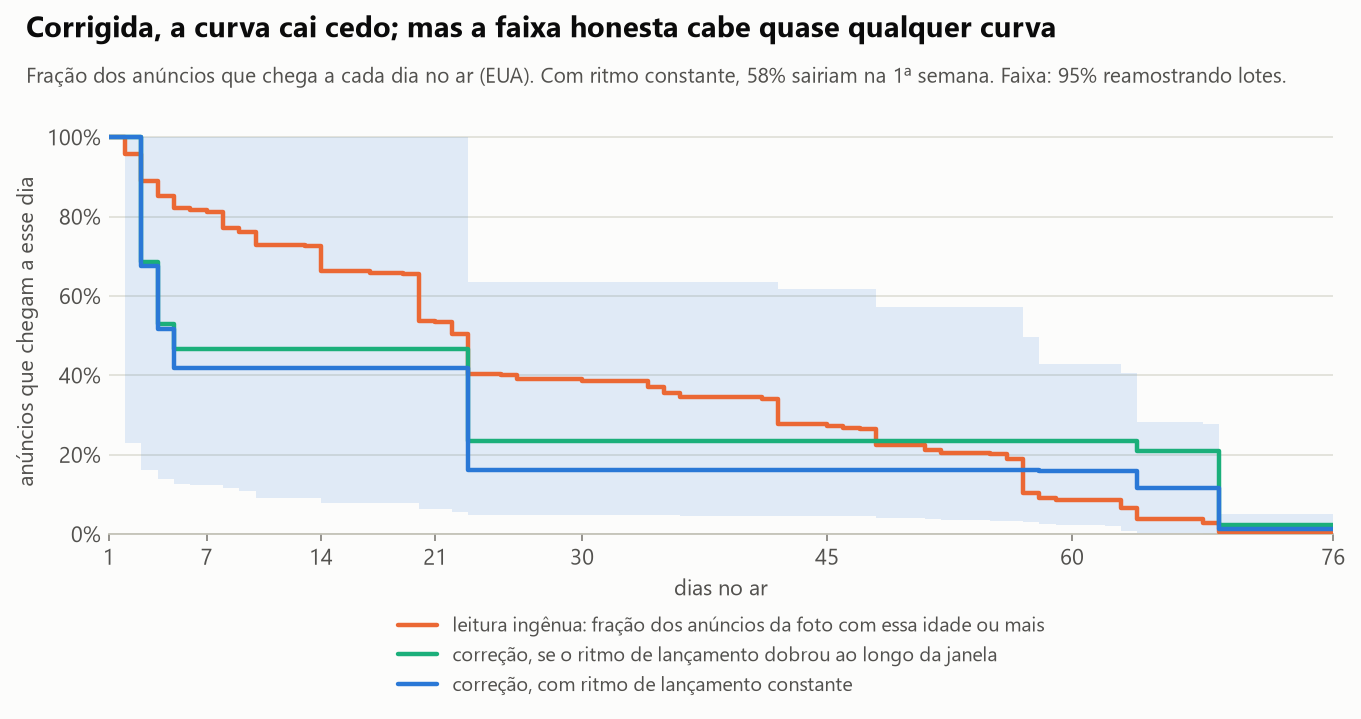

,anúncios com essa idade,leitura ingênua,corrigida,inferior (criativo),superior (criativo),inferior (lote),superior (lote),"corrigida, ritmo 2x","corrigida, ritmo 4x"
dia,,,,,,,,,
1,"52,00","1,00","1,00","1,00","1,00","1,00","1,00","1,00","1,00"
3,"47,00","0,89","0,68","0,38","1,00","0,16","1,00","0,69","0,70"
5,"7,00","0,82","0,42","0,26","0,69","0,13","1,00","0,47","0,52"
8,"14,00","0,77","0,42","0,26","0,68","0,12","1,00","0,47","0,52"
15,"0,00","0,66","0,42","0,26","0,68","0,08","1,00","0,47","0,52"
23,"0,00","0,40","0,16","0,10","0,28","0,05","0,64","0,23","0,34"
31,"0,00","0,39","0,16","0,10","0,28","0,05","0,64","0,23","0,34"
45,"6,00","0,27","0,16","0,10","0,28","0,05","0,62","0,23","0,34"
61,"2,00","0,09","0,16","0,04","0,27","0,02","0,43","0,23","0,34"


In [5]:
curva = analise.curva_de_sobrevivencia(eua)
mostrar(graficos.sobrevivencia(curva, duracao))
curva[curva["dia"].isin([1, 3, 5, 8, 15, 23, 31, 45, 61, 76])].set_index("dia")

A leitura ingênua diz 27,6 dias. A correção, **sob a hipótese de ritmo constante**, diz 18: seriam cerca de 5.300
anúncios lançados em 76 dias, dos quais 76% já saíram do ar e não aparecem. Mas a hipótese importa, e a foto não a
confere: `n(a)` só identifica o produto `w(a) × S(a)`. Qualquer queda nas contagens pode ser "os anúncios morrem" ou
"lançava-se menos naquela época".

## 3. O próprio dado contradiz o ritmo constante: os anúncios sobem em lotes

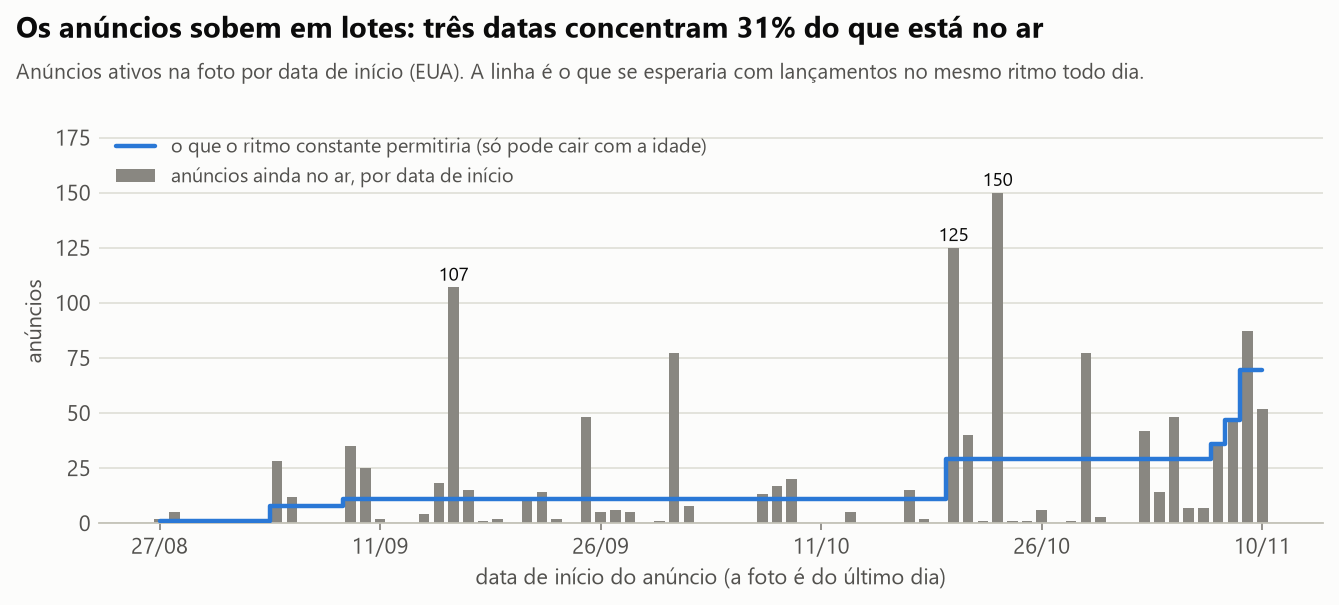

,BR,US
janela (dias),"20,00","76,00"
datas com lançamento,"4,00","48,00"
anúncios por data (mediana),"9,00","12,50"
maior lote (anúncios),"74,00","150,00"
maior lote (fração),"0,80","0,12"
três maiores lotes (fração),"0,99","0,31"
dias entre lançamentos (mediana),"4,00","1,00"
lançados nos últimos 7 dias (fração),"0,08","0,23"
índice de dispersão,"34,29","39,67"


In [6]:
lotes = analise.lotes(anuncios)
mostrar(graficos.lotes(analise.lancamentos_por_data(eua), lotes.loc["US"]))
lotes.T

O índice de dispersão compara a variação das contagens por dia com a de um Poisson em torno da curva ajustada: 1
seria "lançamentos independentes"; aqui é perto de 40. No Brasil, a página tem 20 dias e 4 datas de lançamento: a
"média de 9,9 dias no ar" é só o calendário de quando a conta começou.

Sensibilidade: a mesma foto lida com outros ritmos. `razão` = lançamentos por dia hoje ÷ no início da janela.

In [7]:
analise.sensibilidade_ao_ritmo(eua)

,duração média,inferior (lote),superior (lote),lançados na janela,já saíram do ar,chegam ao dia 31
razão do ritmo,,,,,,
"0,25","12,39","4,80","31,96","11.348,29","10.099,29","0,08"
"0,50","14,74","5,58","36,33","7.589,12","6.340,12","0,11"
"1,00","17,97","6,59","42,99","5.282,00","4.033,00","0,16"
"2,00","22,44","7,92","51,22","3.829,79","2.580,79","0,23"
"4,00","28,62","9,69","61,73","2.890,00","1.641,00","0,34"
"8,00","37,02","11,95","68,39","2.263,53","1.014,53","0,49"


## 4. Anúncios não são independentes: o intervalo certo reamostra blocos

O mesmo criativo aparece em vários anúncios, e os anúncios de um lote compartilham a data. O bootstrap que sorteia
anúncios soltos trata 1.249 linhas como 1.249 informações. Abaixo, o mesmo intervalo de 95% sorteando anúncios,
grupos de criativo inteiros e lotes inteiros.

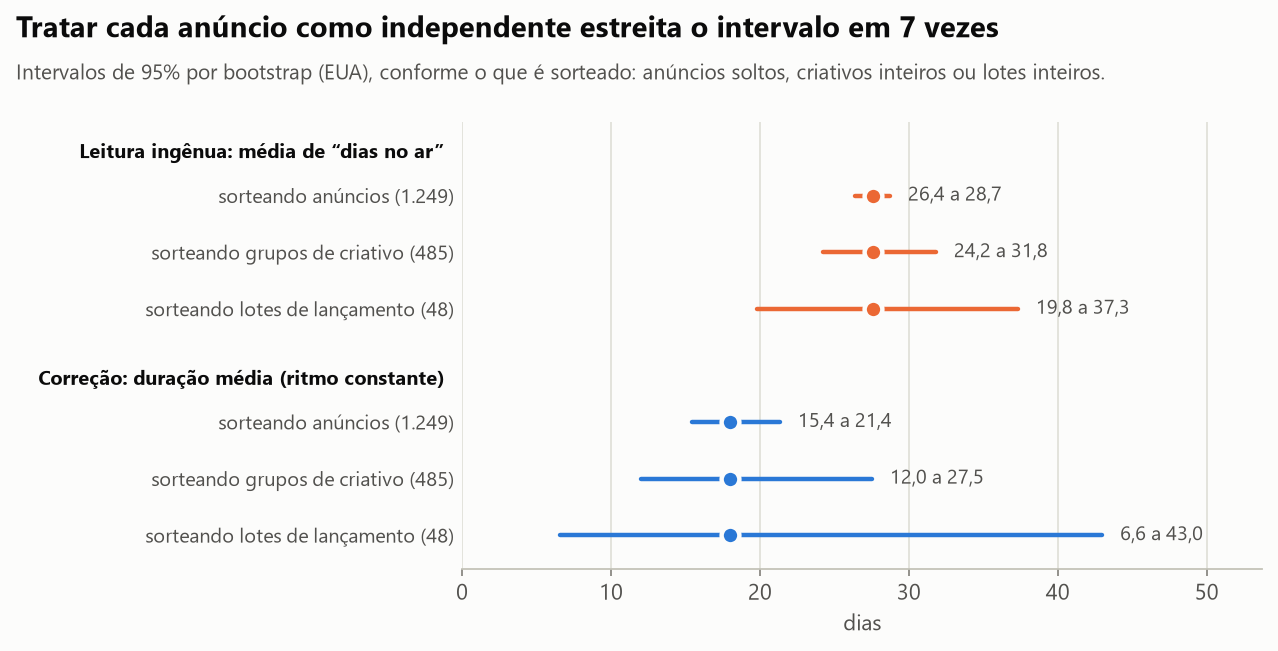

,anúncio,grupo de criativo,lote de lançamento
blocos,"1.249,00","485,00","48,00"
ingênua inferior,"26,39","24,24","19,81"
ingênua superior,"28,74","31,83","37,33"
corrigida inferior,"15,42","12,00","6,59"
corrigida superior,"21,35","27,53","42,99"
lançados inferior,"4.446,00","3.381,68","1.963,90"
lançados superior,"6.156,00","8.360,95","15.808,00"
largura ingênua,"2,36","7,59","17,52"
largura corrigida,"5,93","15,53","36,40"
vezes mais largo (ingênua),"1,00","3,22","7,44"


In [8]:
mostrar(graficos.intervalos(duracao))
duracao["tabela"].T

Qual desses intervalos merece confiança? Na simulação a verdade é conhecida, então dá para contar em quantas fotos o
intervalo de 95% a contém:

In [9]:
cobertura = analise.cobertura_dos_intervalos()
cobertura

,ritmo,unidade reamostrada,cobertura (leitura ingênua),cobertura (correção),largura média (leitura ingênua),largura média (correção)
0,Ritmo constante,anúncio,"0,76","0,76","8,35","7,86"
1,Ritmo constante,grupo de criativo,"0,97","0,94","12,87","12,68"
2,Ritmo constante,lote de lançamento,"1,00","1,00","27,48","49,44"
3,Lançamentos em lotes irregulares,anúncio,"0,23","0,05","9,22","9,64"
4,Lançamentos em lotes irregulares,grupo de criativo,"0,29","0,06","14,26","14,79"
5,Lançamentos em lotes irregulares,lote de lançamento,"0,79","0,67","64,61","106,07"


Com ritmo constante, o intervalo por anúncio cobre a verdade em cerca de três quartos das fotos, e o por criativo
chega perto dos 95% prometidos. Com lançamentos em lotes, **nem o intervalo por criativo serve** (cobre menos de 30%);
o por lote é o menos errado, e ainda assim fica abaixo de 95%. O intervalo de 7 a 43 dias é, portanto, otimista.

## 5. Estrutura do portfólio de criativos: Brasil e Estados Unidos

In [10]:
estrutura = analise.estrutura_do_portfolio(anuncios)
pd.DataFrame(estrutura["numeros"]).drop(index="idiomas")

,BR,US
anúncios,93,1249
criativos distintos,89,485
anúncios por criativo (média),"1,04","2,58"
anúncios por criativo (máximo),2,62
criativos com um anúncio só (fração),"0,96","0,38"
10% dos criativos com mais anúncios (fração dos anúncios),"0,14","0,32"
Gini dos anúncios por criativo,"0,04","0,40"
textos distintos,2,58
anúncios por texto (média),"46,50","21,53"
texto mais usado (fração dos anúncios),"0,87","0,16"


In [11]:
proporcoes = pd.concat({pais: pd.DataFrame(p).T for pais, p in estrutura["proporcoes"].items()}, axis=1)
proporcoes

BR                            US                           
                                        valor inferior superior     n valor inferior superior        n
formato dinâmico (dco)                   1,00     1,00     1,00 93,00  0,92     0,89     0,94 1.249,00
formato vídeo único                      0,00     0,00     0,00 93,00  0,07     0,05     0,10 1.249,00
formato imagem                           0,00     0,00     0,00 93,00  0,01     0,00     0,02 1.249,00
promete prévia grátis                    0,87     0,79     0,94 93,00  0,50     0,43     0,57 1.249,00
prova social no texto ou título          0,00     0,00     0,00 93,00  0,50     0,43     0,57 1.249,00
prova social na descrição                0,00     0,00     0,00 93,00  0,88     0,84     0,91 1.249,00
urgência                                 0,00     0,00     0,00 93,00  0,21     0,16     0,26 1.249,00
cita ocasião ou data                     0,00     0,00     0,00 93,00  0,11     0,08     0,14 1.249,00
cita Natal                               0,00     0,00     0,00 93,00  0,00     0,00     0,00 1.249,00
cita preço                               0,00     0,00     0,00 93,00  0,00     0,00     0,00 1.249,00
tem pergunta                             0,00     0,00     0,00 93,00  0,07     0,05     0,08 1.249,00
gancho de reação emocionada              1,00     1,00     1,00 93,00  0,47     0,39     0,53 1.249,00
gancho de prova social                   0,00     0,00     0,00 93,00  0,36     0,29     0,44 1.249,00
vídeo real (entre os classificados)      0,94     0,88     0,98 93,00  0,93     0,86     0,99   553,00
cena de reação (entre os classificados)  0,92     0,87     0,97 93,00  0,81     0,71     0,89   553,00

Nos EUA, 485 criativos viram 1.249 anúncios (2,6 por criativo; os 10% mais usados respondem por 32% dos anúncios), com
58 textos. No Brasil, 89 criativos em 93 anúncios e **dois textos**: o teste é de vídeo, não de texto. Nenhum anúncio,
em nenhum dos dois países, cita preço ou Natal.

## 6. Que atributos andam junto com a idade?

Para cada atributo, a diferença de idade média entre anúncios com e sem ele, com intervalo reamostrando criativos. O
p-valor é calculado três vezes, embaralhando a idade entre anúncios (leitura ingênua), entre criativos e entre lotes,
sempre com ajuste de Benjamini-Hochberg.

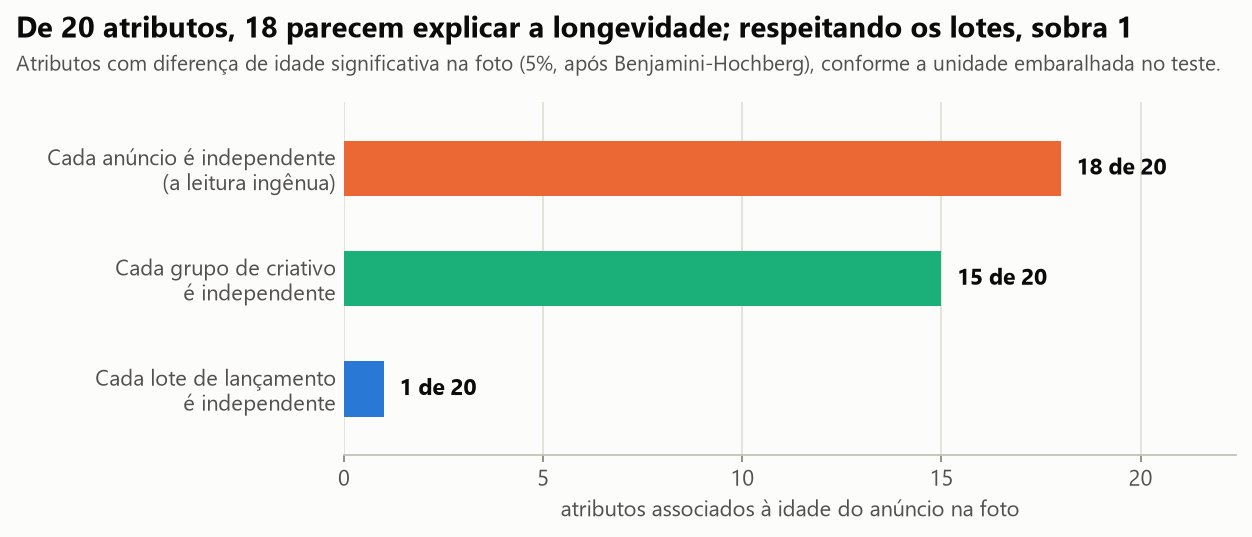

{'atributos testados': 20,
 'significativos por anúncio': 18,
 'significativos por criativo': 15,
 'significativos por lote': 1,
 'menor p ajustado por lote': 0.00999750062484379,
 'que passam por lote': ['Veicula em 5 ou mais plataformas']}

In [12]:
atributos = analise.atributos_e_idade(eua)
resumo_atributos = analise.resumo_dos_atributos(atributos)
mostrar(graficos.rigor(resumo_atributos))
resumo_atributos

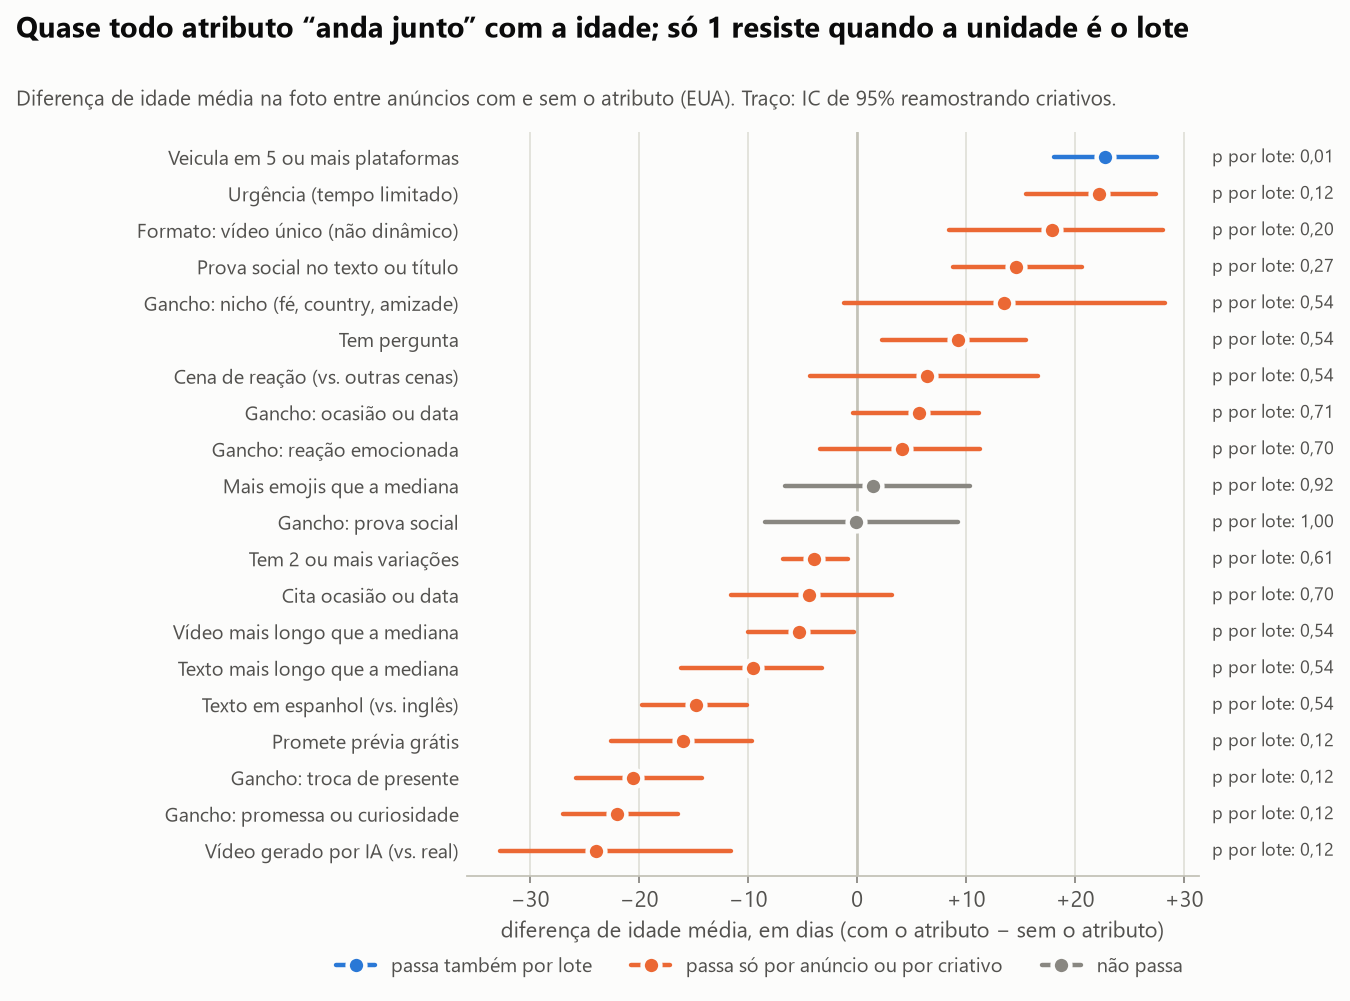

,com o atributo,lotes com o atributo,diferença (dias),IC 95% inferior,IC 95% superior,p ajustado por anúncio,p ajustado por criativo,p ajustado por lote
Veicula em 5 ou mais plataformas,"608,00","29,00","22,74","18,07","27,49","0,00","0,00","0,01"
Urgência (tempo limitado),"263,00","18,00","22,17","15,48","27,41","0,00","0,00","0,12"
Formato: vídeo único (não dinâmico),"92,00","13,00","17,92","8,44","28,10","0,00","0,00","0,20"
Prova social no texto ou título,"626,00","33,00","14,59","8,76","20,65","0,00","0,00","0,27"
"Gancho: nicho (fé, country, amizade)","37,00","6,00","13,45","-1,17","28,28","0,00","0,01","0,54"
Tem pergunta,"82,00","9,00","9,24","2,31","15,46","0,00","0,00","0,54"
Cena de reação (vs. outras cenas),"447,00","19,00","6,43","-4,35","16,58","0,00","0,23","0,54"
Gancho: ocasião ou data,"73,00","9,00","5,67","-0,42","11,21","0,03","0,02","0,71"
Gancho: reação emocionada,"582,00","32,00","4,10","-3,44","11,25","0,00","0,23","0,70"
Mais emojis que a mediana,"452,00","25,00","1,49","-6,58","10,40","0,25","0,68","0,92"


In [13]:
mostrar(graficos.atributos(atributos))
atributos[["com o atributo", "lotes com o atributo", "diferença (dias)", "IC 95% inferior", "IC 95% superior", "p ajustado por anúncio", "p ajustado por criativo", "p ajustado por lote"]]

Pela leitura ingênua, 18 de 20 atributos "explicam" a longevidade. Com a unidade certa, sobra 1, e ele é uma
configuração de campanha (em quantas plataformas o anúncio veicula), não uma escolha criativa.

O que isso significa: a idade na foto é, antes de tudo, **a data em que o lote subiu**. Um texto em espanhol lançado
todo de uma vez há 22 dias tem "idade média de 16 dias" porque foi lançado há pouco, não porque dura menos. E o teste
por lote tem só 48 lotes: não passar não prova que o atributo é irrelevante; mostra que a foto não tem informação para
decidir.

## 7. Um sinal um pouco melhor que a idade: o que o anunciante volta a lançar

In [14]:
relancamento = analise.relancamento(eua)
pd.Series({k: v for k, v in relancamento.items() if not isinstance(v, dict)})

criativos                                            485,00
correlação de postos entre idade e número de lotes     0,39
correlação inferior                                    0,31
correlação superior                                    0,46
limiar de antigo (dias)                               30,00
limiar de recente (dias)                              14,00
antigos                                              165,00
fração dos antigos que foi relançada                   0,04
dos 20 mais antigos, relançados recentemente           0,00
dos 20 mais antigos, em um lote só                    17,00
dtype: float64

In [15]:
pd.DataFrame({"antigos e relançados": relancamento["antigos relançados"], "antigos e parados": relancamento["antigos parados"]})

,antigos e relançados,antigos e parados
criativos,7,158
anúncios,80,437
lotes (mediana),"2,00","1,00"
"duração do vídeo (mediana, s)","57,00","57,00"
categorias do gancho,{'prova_social': 1.0},"{'reacao': 0.5, 'prova_social': 0.2342, 'ocasi..."
cenas (entre os classificados),"{'reacao': 0.5, 'animacao': 0.5}","{'reacao': 0.8478, 'outro': 0.1304, 'depoiment..."
com classificação,2,46


Dos 165 criativos com 30 dias ou mais, só 7 reaparecem num anúncio lançado nos últimos 14 dias. Os outros 158 estão
no ar sem que ninguém tenha mexido neles: pode ser porque funcionam, pode ser inércia. A foto não distingue.

## 8. Ponte para a decisão

A categoria do gancho (a abertura do texto) nos anúncios do concorrente.

In [16]:
analise.categorias_de_gancho(anuncios)

,EUA: fração dos anúncios,EUA: fração dos anúncios com 30 dias ou mais,Brasil: fração dos anúncios
Preço,"0,00","0,00","0,00"
Prova social,"0,36","0,28","0,00"
Reação emocionada,"0,47","0,59","1,00"
Troca de presente,"0,04","0,00","0,00"
"Nicho (fé, country, amizade)","0,03","0,06","0,00"
Ocasião ou data,"0,06","0,07","0,00"
Oferta ou objeção,"0,01","0,00","0,00"
Promessa ou curiosidade,"0,04","0,00","0,00"


Reação emocionada e prova social dominam o concorrente. A coluna de anúncios mostra o que o líder lança; a de 30
dias ou mais, o que ele lançou antes; nenhuma mede resultado.

## O que dá para concluir

- **O que o líder mantém no ar** dá para descrever com segurança: reação emocionada e prova social nos textos, vídeo
  de reação real de cerca de um minuto, um texto para muitos vídeos, lançamentos em lotes, nada de preço e nada de
  Natal.
- **O que funciona** a foto não diz. "Dias no ar" mede quando o lote subiu. A duração típica de um anúncio fica em
  algum lugar entre 7 e 43 dias, e nenhuma escolha criativa se associa à idade quando a unidade é o lote.
- **"Dias no ar" serve para escolher referência de formato**, não como evidência de desempenho.
- **O que resolveria:** fotos semanais. Com duas fotos já se vê quem saiu do ar; com seis, a curva de sobrevivência
  deixa de depender da hipótese de ritmo.
- **O que testar:** o ângulo próprio contra o ângulo dominante do líder, com a mesma verba por criativo. É hipótese
  para teste, não conclusão deste estudo.